# Población nacida en el extranjero y empleo de los nacidos en el país con estudios básicos

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "poblacion-extranjera-empleo-nativos-estudios-bajos"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Población nacida en el extranjero y empleo de los nacidos en el país con estudios básicos"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ue27"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Población nacida en el extranjero", "unidad": "% de la población de 20 a 64 años"}
EJE_Y = {"titulo": "Tasa de empleo de los nacidos en el país con estudios básicos", "unidad": "% de la población de 20 a 64 años nacida en el país con estudios básicos"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la UE-27 con dato en los dos ejes.

- **Eje horizontal:** el **porcentaje de la población de 20 a 64 años nacida en el extranjero** (el mismo que en `poblacion-extranjera-empleo-nativos`).
- **Eje vertical:** la **tasa de empleo de las personas de 20 a 64 años nacidas en el país que no han terminado la segunda etapa de secundaria** (niveles 0 a 2 de la CINE: hasta la ESO en España).

**Para qué sirve.** Es el argumento de quienes sostienen que la inmigración compite con los trabajadores nacidos en el país de menor cualificación, que son los que más a menudo trabajan en las mismas ocupaciones; su pareja es `poblacion-extranjera-empleo-nativos`, con todos los nacidos en el país. **La relación entre dos indicadores no muestra que uno cause el otro**: la inmigración se dirige a los países y años con más demanda de trabajo. No se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El peso de las personas con estudios básicos en la población varía mucho entre países, y con él lo que representa este grupo.
- Se usa el país de nacimiento, no la nacionalidad.
- Universo: UE-27, porque los dos ejes solo existen en Eurostat. Cada punto usa el último año en que el país tiene dato en los dos ejes.

## 2. Descarga

- **Eje x: Eurostat `migr_pop3ctb`**: población a 1 de enero por país de nacimiento (`c_birth=FOR` y `TOTAL`), ambos sexos, por grupos quinquenales de edad de `Y20-24` a `Y60-64`, que se suman (la misma descarga que `poblacion-extranjera-empleo-nativos`).
- **Eje y: Eurostat `lfsa_ergaedcob`**: tasa de empleo (`PC`) de 20 a 64 años de la población nacida en el país (`c_birth=NAT`) con estudios de los niveles 0 a 2 de la CINE (`isced11=ED0-2`), ambos sexos.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from lib import eurostat
from lib.paises import CODIGOS_EUROSTAT
from lib.tipos import FuenteMeta

GEOS = {**{CODIGOS_EUROSTAT[c]: c for c in PAISES}, "EU27_2020": "EU27_2020"}  # código Eurostat → clave de la serie
GRUPOS = ["Y20-24", "Y25-29", "Y30-34", "Y35-39", "Y40-44", "Y45-49", "Y50-54", "Y55-59", "Y60-64"]


def poblacion(c_birth):
    """Población de 20 a 64 años a 1 de enero (suma de los grupos quinquenales), solo los años con todos los grupos."""
    partes = []
    for g in GRUPOS:
        d, _ = eurostat.get("migr_pop3ctb", {"c_birth": c_birth, "age": g, "sex": "T", "unit": "NR"}, geos=GEOS, desde=DESDE)
        partes.append(d.set_index(["serie", "periodo"])["valor"].rename(g))
    return pd.concat(partes, axis=1).dropna().sum(axis=1)


extranjero, total = poblacion("FOR"), poblacion("TOTAL")
y, fuentes_y = eurostat.get(
    "lfsa_ergaedcob", {"c_birth": "NAT", "isced11": "ED0-2", "age": "Y20-64", "sex": "T", "unit": "PC"}, geos=GEOS, desde=DESDE
)
estados_y, _ = eurostat.get_estados(
    "lfsa_ergaedcob", {"c_birth": "NAT", "isced11": "ED0-2", "age": "Y20-64", "sex": "T", "unit": "PC"}, geos=GEOS, desde=DESDE
)
print("Países con población:", extranjero.index.get_level_values(0).nunique(), "· con tasa de empleo:", y["serie"].nunique())

Países con población: 28 · con tasa de empleo: 28


## 3. Transformación

1. **Eje x:** población nacida en el extranjero entre la población total, de 20 a 64 años, por 100, en los años en que están todos los grupos de edad.
2. **Eje y:** se usa tal como lo publica Eurostat.
3. **Punto de la UE-27:** Eurostat publica el agregado (`EU27_2020`) en los dos ejes; el escritor lo añade si coincide algún año.
4. **Fiabilidad:** se anotan los puntos cuyo año Eurostat marca con fiabilidad baja en el eje y.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")

x = (extranjero / total * 100).dropna().rename("valor").reset_index()
assert x["valor"].between(0, 100).all(), "porcentaje fuera de rango"
HOY = fuentes_y[0].fecha_consulta
URL_POB = eurostat.URL_DATABROWSER.format(dataset="migr_pop3ctb")
fuentes = [
    FuenteMeta("eje_x", eurostat.ORGANISMO, "migr_pop3ctb (sex=T, unit=NR, de Y20-24 a Y60-64): c_birth=FOR entre c_birth=TOTAL", URL_POB, HOY),
    FuenteMeta("eje_y", eurostat.ORGANISMO, "lfsa_ergaedcob (c_birth=NAT, isced11=ED0-2, sex=T, age=Y20-64, unit=PC)", fuentes_y[0].url, HOY),
]
NOTAS = [
    "Población nacida en el extranjero: Eurostat (migr_pop3ctb), población a 1 de enero de 20 a 64 años nacida en el "
    "extranjero (c_birth=FOR) entre la población total de esa edad, suma de los grupos quinquenales de 20 a 64 años; "
    "solo los años con todos los grupos publicados. Es la población a 1 de enero; la tasa de empleo es la media del año.",
    "La inmigración se dirige a los países y los años con más demanda de trabajo, así que la relación entre los dos "
    "indicadores no muestra el efecto de la inmigración sobre el empleo; la evidencia causal se resume en la del enfoque "
    "vias_inmigracion de seguridad social.",
    "Tasa de empleo: Eurostat (lfsa_ergaedcob), ocupados de 20 a 64 años nacidos en el país con estudios de los niveles "
    "0 a 2 de la CINE (sin la segunda etapa de secundaria) en % de la población de esa edad y estudios nacida en el país.",
    "El peso de las personas con estudios básicos en la población varía mucho entre países, y con él lo que representa "
    "este grupo.",
    "Media UE-27: los agregados de composición actual (EU27_2020) que publica Eurostat en los dos ejes.",
]
# Puntos cuyo año Eurostat marca con fiabilidad baja (u) en el eje y
from lib.paises import nombre_punto
previos = construir_dispersion_data(x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=[],
                                    generado_por="", desde=DESDE, anios=ANIOS)["puntos"]
marca = estados_y.set_index(["serie", "periodo"])["estado"]
baja = [f"{nombre_punto(p['codigo'])} ({p['anio']})" for p in previos
        if "u" in str(marca.get((p["codigo"], p["anio"]), ""))]
if baja:
    NOTAS.append("Eurostat marca con fiabilidad baja el dato del eje vertical de: " + ", ".join(baja) + ".")
for n in NOTAS:
    print("-", n)

- Población nacida en el extranjero: Eurostat (migr_pop3ctb), población a 1 de enero de 20 a 64 años nacida en el extranjero (c_birth=FOR) entre la población total de esa edad, suma de los grupos quinquenales de 20 a 64 años; solo los años con todos los grupos publicados. Es la población a 1 de enero; la tasa de empleo es la media del año.
- La inmigración se dirige a los países y los años con más demanda de trabajo, así que la relación entre los dos indicadores no muestra el efecto de la inmigración sobre el empleo; la evidencia causal se resume en la del enfoque vias_inmigracion de seguridad social.
- Tasa de empleo: Eurostat (lfsa_ergaedcob), ocupados de 20 a 64 años nacidos en el país con estudios de los niveles 0 a 2 de la CINE (sin la segunda etapa de secundaria) en % de la población de esa edad y estudios nacida en el país.
- El peso de las personas con estudios básicos en la población varía mucho entre países, y con él lo que representa este grupo.
- Media UE-27: los agregados 

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

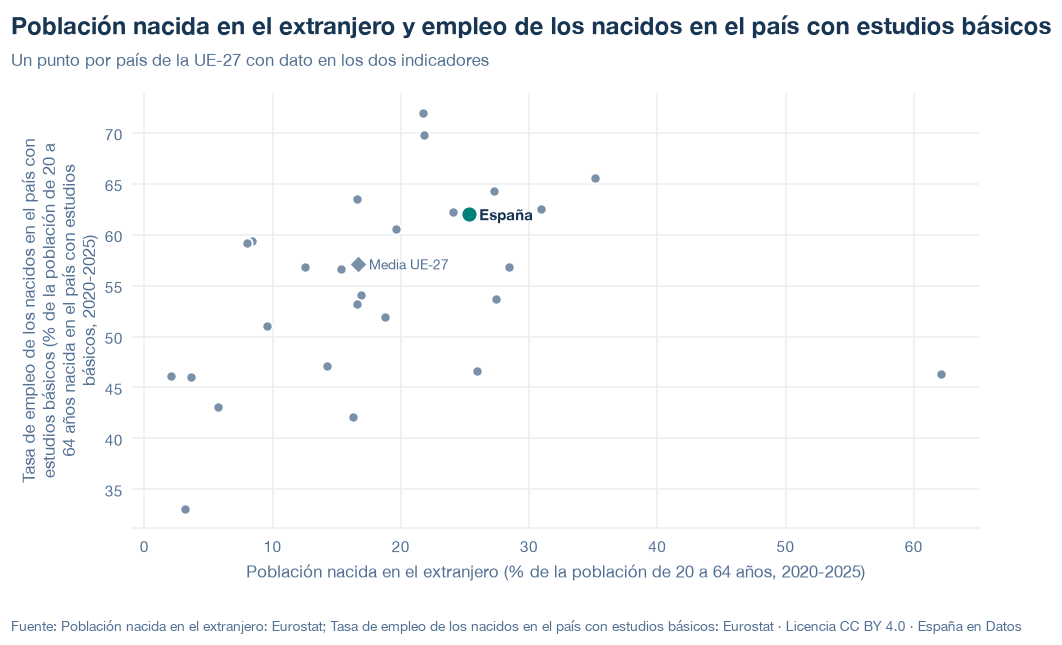

   codigo  anio         x    y
      AUT  2025 28.428245 56.8
      BEL  2025 25.918543 46.6
      BGR  2025  3.663096 46.0
      CYP  2025 35.108518 65.6
      CZE  2025 12.522280 56.8
      DEU  2025 24.095015 62.2
      DNK  2025 19.652846 60.6
      ESP  2025 25.284186 62.0
      EST  2025 16.553015 63.5
      FIN  2025 14.270356 47.1
      FRA  2025 16.912824 54.1
      GRC  2025 15.316604 56.6
      HRV  2025 16.304920 42.1
      HUN  2025  8.390995 59.4
      IRL  2025 27.391257 53.7
      ITA  2025 16.554659 53.2
      LTU  2025  9.557338 51.0
      LUX  2025 62.086624 46.3
      LVA  2025  7.980433 59.2
      MLT  2020 30.921930 62.5
      NLD  2025 21.755549 72.0
      POL  2025  2.042761 46.1
      PRT  2024 21.797002 69.8
      ROU  2025  5.732898 43.1
      SVK  2025  3.151303 33.1
      SVN  2025 18.734520 51.9
      SWE  2025 27.253687 64.3
EU27_2020  2023 16.684120 57.1


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/poblacion-extranjera-empleo-nativos-estudios-bajos.json y data/poblacion-extranjera-empleo-nativos-estudios-bajos.csv


## 6. Fuentes, notas y licencia

- Eurostat, `migr_pop3ctb` (`c_birth=FOR` y `TOTAL`, `sex=T`, `unit=NR`, grupos de `Y20-24` a `Y60-64`).
- Eurostat, `lfsa_ergaedcob` (`c_birth=NAT`, `isced11=ED0-2`, `sex=T`, `age=Y20-64`, `unit=PC`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.